# Part 1 – Transfer learning on CIFAR-100 (VGG-16 vs. ResNet-50)

Preliminary experiment: ImageNet-pretrained VGG-16 and ResNet-50 with frozen backbones and a new classification head, trained for 10 epochs with 50%, 60% and 70% training splits.


In [12]:
# Import Libraries
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import torchvision.models as models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import time
from tqdm import tqdm
import pandas as pd

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [14]:
# Data transformations 
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])

In [15]:
# Load CIFAR-100 dataset
train_full = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

Files already downloaded and verified
Files already downloaded and verified


VGG-16

In [16]:
# Load VGG16 model 
def get_vgg16():
    from torchvision.models import VGG16_Weights
    model = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

    for param in model.parameters():
        param.requires_grad = False
    model.classifier[6] = nn.Linear(4096, 100)

    for param in model.classifier[6].parameters():
        param.requires_grad = True
        
    return model

ResNet-50

In [17]:
# Load RESNET50 model
def get_resnet50():
    from torchvision.models import ResNet50_Weights
    model = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1) 

    for param in model.parameters():
        param.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 100)

    for param in model.fc.parameters():
        param.requires_grad = True
        
    return model

In [18]:
# Initialization
results = {
    'model': [],
    'split_ratio': [],
    'train_acc': [],
    'val_acc': [],
    'test_acc': [],
}

In [19]:
# Training Function 
def train_model(model, train_loader, val_loader, epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        # Progress bar with tqdm
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} - Training"):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)

        # Validation
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_loss /= total
        val_acc = correct / total
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        print("Train Loss: {:.4f}, Train Accuracy: {:.4f}, Validation Loss: {:.4f}, Validation Accuracy: {:.4f}".format(train_loss, train_acc, val_loss, val_acc))

    total_time = time.time() - start_time
    print("Training completed in {:.2f} seconds".format(total_time))

    return train_losses, val_losses, train_accuracies, val_accuracies

In [20]:
# Evaluation model
def evaluate_model(model, test_loader): 

    model.eval()
    preds, true = [], []

    with torch.no_grad():

        for inputs, labels in test_loader:

            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            preds.extend(predicted.cpu().numpy())
            true.extend(labels.numpy())
    
    return {
        'accuracy': accuracy_score(true, preds),
        'precision': precision_score(true, preds, average='macro', zero_division=0),
        'recall': recall_score(true, preds, average='macro', zero_division=0),
        'f1': f1_score(true, preds, average='macro', zero_division=0)
    }

In [21]:
# Plots
def plot_metrics(train_losses, val_losses, train_accs, val_accs, model_name, split_ratio):
    plt.figure(figsize=(12, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Val Loss')
    plt.title(f'{model_name} Loss ({int(split_ratio * 100)}%)')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(train_accs, label='Train Accuracy')
    plt.plot(val_accs, label='Val Accuracy')
    plt.title(f'{model_name} Accuracy ({int(split_ratio * 100)}%)')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()


VGG16 - 50%
Train Loss: 2.0431, Train Accuracy: 0.4579, Validation Loss: 1.5309, Validation Accuracy: 0.5635
Train Loss: 1.5518, Train Accuracy: 0.5604, Validation Loss: 1.4592, Validation Accuracy: 0.5842
Train Loss: 1.4295, Train Accuracy: 0.5907, Validation Loss: 1.4551, Validation Accuracy: 0.5879
Train Loss: 1.3486, Train Accuracy: 0.6090, Validation Loss: 1.4500, Validation Accuracy: 0.5894
Train Loss: 1.2994, Train Accuracy: 0.6267, Validation Loss: 1.4512, Validation Accuracy: 0.5923
Train Loss: 1.2606, Train Accuracy: 0.6320, Validation Loss: 1.4345, Validation Accuracy: 0.5994
Train Loss: 1.2234, Train Accuracy: 0.6436, Validation Loss: 1.4618, Validation Accuracy: 0.5968
Train Loss: 1.1813, Train Accuracy: 0.6508, Validation Loss: 1.4587, Validation Accuracy: 0.6013
Train Loss: 1.1674, Train Accuracy: 0.6525, Validation Loss: 1.4576, Validation Accuracy: 0.6030
Train Loss: 1.1547, Train Accuracy: 0.6605, Validation Loss: 1.4798, Validation Accuracy: 0.6030
Training complete

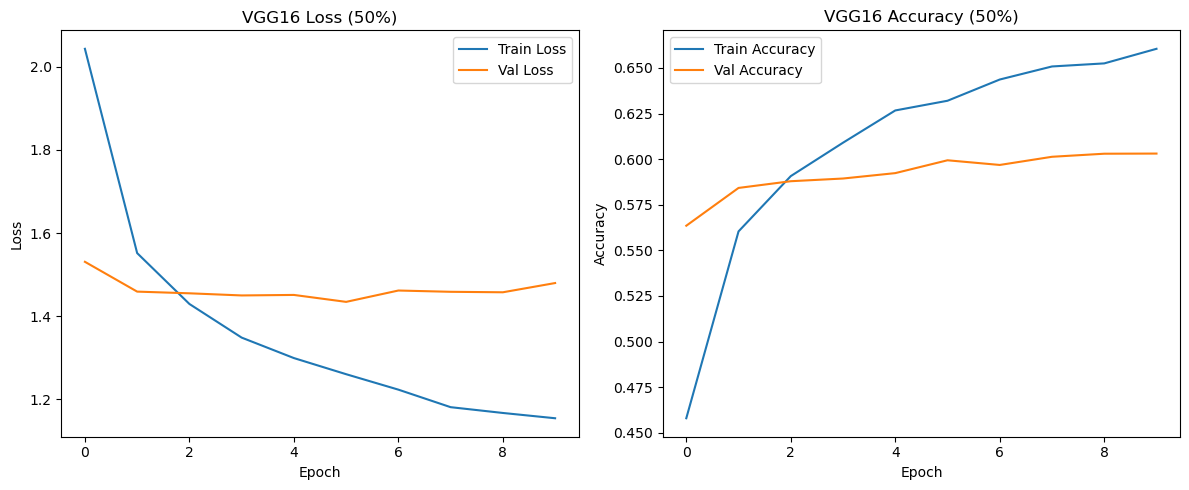


Final Evaluation for VGG16 (50%):
Accuracy: 0.6069
Precision: 0.6258
Recall: 0.6069
F1: 0.6024

VGG16 - 60%
Train Loss: 2.0081, Train Accuracy: 0.4670, Validation Loss: 1.5288, Validation Accuracy: 0.5615
Train Loss: 1.5712, Train Accuracy: 0.5620, Validation Loss: 1.4400, Validation Accuracy: 0.5858
Train Loss: 1.4544, Train Accuracy: 0.5860, Validation Loss: 1.4431, Validation Accuracy: 0.5913
Train Loss: 1.3949, Train Accuracy: 0.5986, Validation Loss: 1.4419, Validation Accuracy: 0.5906
Train Loss: 1.3504, Train Accuracy: 0.6146, Validation Loss: 1.4084, Validation Accuracy: 0.6028
Train Loss: 1.2956, Train Accuracy: 0.6278, Validation Loss: 1.4057, Validation Accuracy: 0.6075
Train Loss: 1.2965, Train Accuracy: 0.6270, Validation Loss: 1.4551, Validation Accuracy: 0.5994
Train Loss: 1.2531, Train Accuracy: 0.6409, Validation Loss: 1.4337, Validation Accuracy: 0.6037
Train Loss: 1.2615, Train Accuracy: 0.6386, Validation Loss: 1.4419, Validation Accuracy: 0.6088
Train Loss: 1.2340

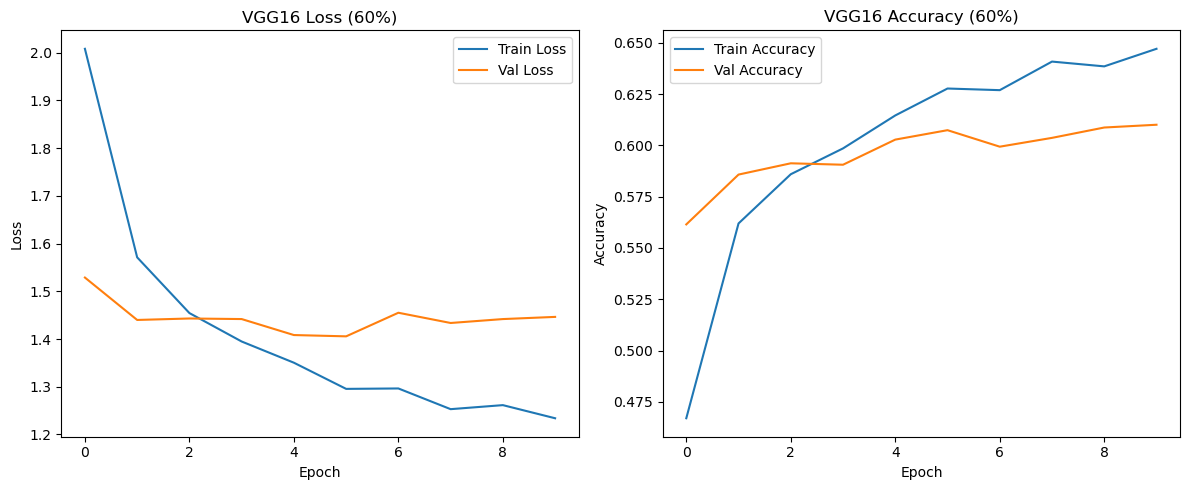


Final Evaluation for VGG16 (60%):
Accuracy: 0.6045
Precision: 0.6218
Recall: 0.6045
F1: 0.6001

VGG16 - 70%
Train Loss: 1.9647, Train Accuracy: 0.4773, Validation Loss: 1.4592, Validation Accuracy: 0.5842
Train Loss: 1.5614, Train Accuracy: 0.5587, Validation Loss: 1.4222, Validation Accuracy: 0.5951
Train Loss: 1.4787, Train Accuracy: 0.5809, Validation Loss: 1.3995, Validation Accuracy: 0.6048
Train Loss: 1.4258, Train Accuracy: 0.5945, Validation Loss: 1.4107, Validation Accuracy: 0.6073
Train Loss: 1.3888, Train Accuracy: 0.6071, Validation Loss: 1.4158, Validation Accuracy: 0.6094
Train Loss: 1.3599, Train Accuracy: 0.6133, Validation Loss: 1.4040, Validation Accuracy: 0.6097
Train Loss: 1.3464, Train Accuracy: 0.6197, Validation Loss: 1.4143, Validation Accuracy: 0.6133
Train Loss: 1.2995, Train Accuracy: 0.6319, Validation Loss: 1.4280, Validation Accuracy: 0.6083
Train Loss: 1.3076, Train Accuracy: 0.6303, Validation Loss: 1.4177, Validation Accuracy: 0.6156
Train Loss: 1.2969

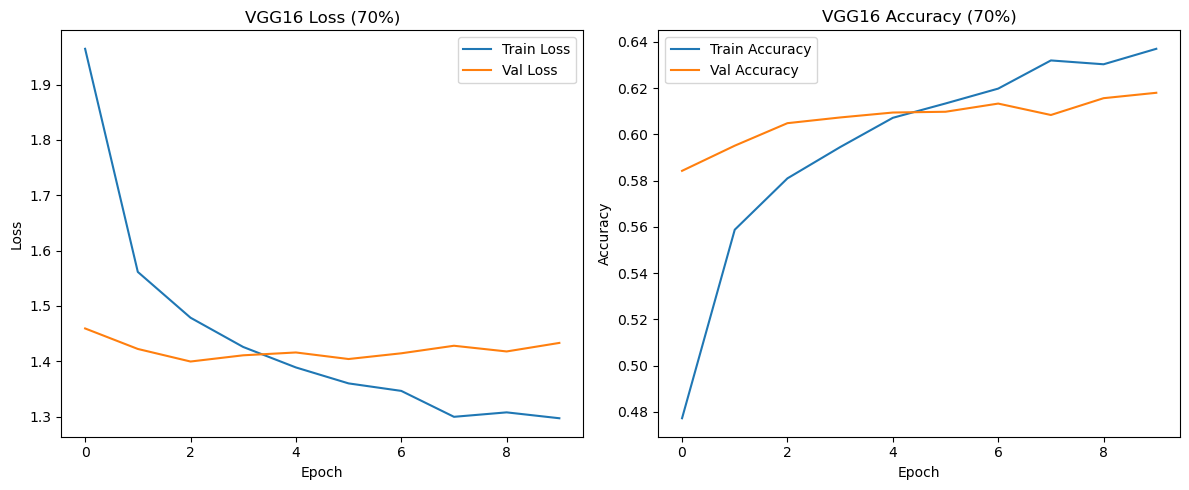


Final Evaluation for VGG16 (70%):
Accuracy: 0.6170
Precision: 0.6334
Recall: 0.6170
F1: 0.6127

ResNet50 - 50%
Train Loss: 2.4955, Train Accuracy: 0.4056, Validation Loss: 1.8498, Validation Accuracy: 0.5096
Train Loss: 1.6122, Train Accuracy: 0.5620, Validation Loss: 1.6135, Validation Accuracy: 0.5564
Train Loss: 1.4222, Train Accuracy: 0.6018, Validation Loss: 1.5929, Validation Accuracy: 0.5629
Train Loss: 1.3226, Train Accuracy: 0.6260, Validation Loss: 1.5632, Validation Accuracy: 0.5734
Train Loss: 1.2407, Train Accuracy: 0.6468, Validation Loss: 1.5705, Validation Accuracy: 0.5680
Train Loss: 1.1925, Train Accuracy: 0.6545, Validation Loss: 1.5543, Validation Accuracy: 0.5780
Train Loss: 1.1452, Train Accuracy: 0.6666, Validation Loss: 1.5933, Validation Accuracy: 0.5710
Train Loss: 1.0925, Train Accuracy: 0.6838, Validation Loss: 1.5585, Validation Accuracy: 0.5803
Train Loss: 1.0562, Train Accuracy: 0.6915, Validation Loss: 1.6022, Validation Accuracy: 0.5716
Train Loss: 1.0

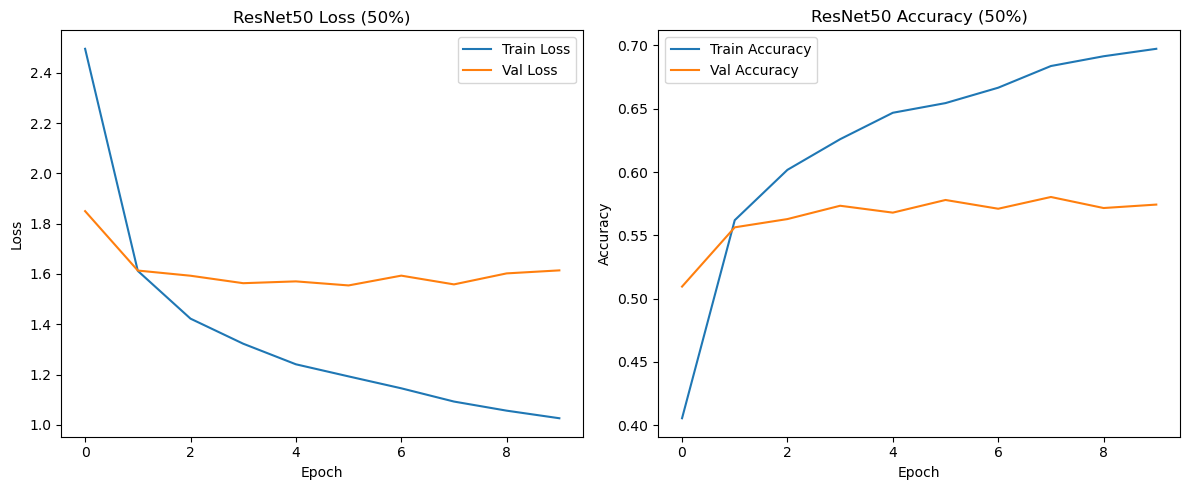


Final Evaluation for ResNet50 (50%):
Accuracy: 0.5733
Precision: 0.6296
Recall: 0.5733
F1: 0.5719

ResNet50 - 60%
Train Loss: 2.4028, Train Accuracy: 0.4163, Validation Loss: 1.7351, Validation Accuracy: 0.5322
Train Loss: 1.5711, Train Accuracy: 0.5729, Validation Loss: 1.6153, Validation Accuracy: 0.5596
Train Loss: 1.4109, Train Accuracy: 0.6047, Validation Loss: 1.5786, Validation Accuracy: 0.5649
Train Loss: 1.3174, Train Accuracy: 0.6280, Validation Loss: 1.5375, Validation Accuracy: 0.5764
Train Loss: 1.2552, Train Accuracy: 0.6433, Validation Loss: 1.5401, Validation Accuracy: 0.5785
Train Loss: 1.2019, Train Accuracy: 0.6535, Validation Loss: 1.5539, Validation Accuracy: 0.5790
Train Loss: 1.1518, Train Accuracy: 0.6701, Validation Loss: 1.5499, Validation Accuracy: 0.5798
Train Loss: 1.1219, Train Accuracy: 0.6743, Validation Loss: 1.5468, Validation Accuracy: 0.5875
Train Loss: 1.0889, Train Accuracy: 0.6826, Validation Loss: 1.5849, Validation Accuracy: 0.5766
Train Loss: 

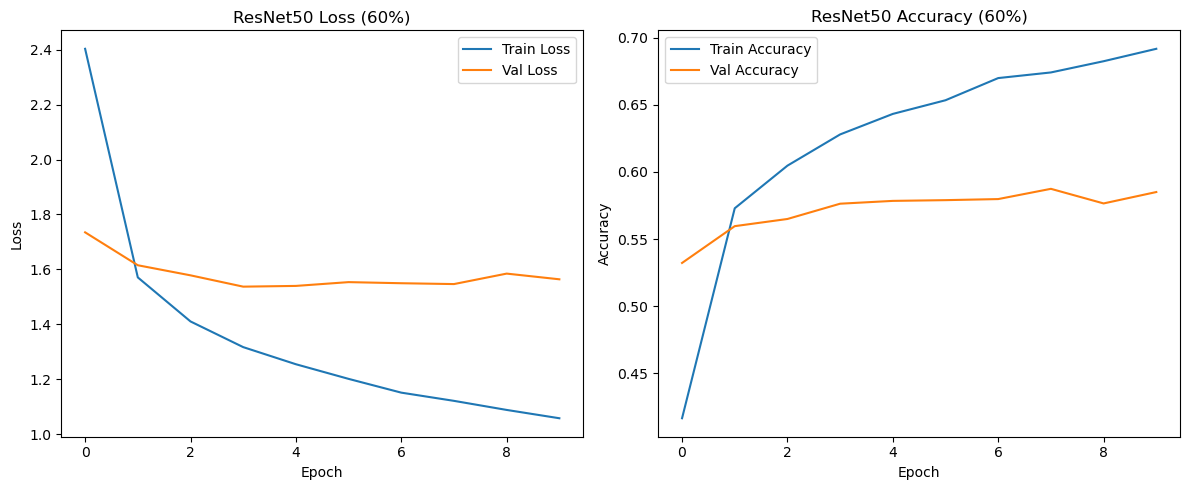


Final Evaluation for ResNet50 (60%):
Accuracy: 0.5837
Precision: 0.6275
Recall: 0.5837
F1: 0.5859

ResNet50 - 70%
Train Loss: 2.3075, Train Accuracy: 0.4317, Validation Loss: 1.6583, Validation Accuracy: 0.5515
Train Loss: 1.5530, Train Accuracy: 0.5733, Validation Loss: 1.5472, Validation Accuracy: 0.5734
Train Loss: 1.4099, Train Accuracy: 0.6042, Validation Loss: 1.5472, Validation Accuracy: 0.5769
Train Loss: 1.3192, Train Accuracy: 0.6260, Validation Loss: 1.5315, Validation Accuracy: 0.5856
Train Loss: 1.2704, Train Accuracy: 0.6385, Validation Loss: 1.4997, Validation Accuracy: 0.5941
Train Loss: 1.2149, Train Accuracy: 0.6517, Validation Loss: 1.5103, Validation Accuracy: 0.5884
Train Loss: 1.1719, Train Accuracy: 0.6618, Validation Loss: 1.5424, Validation Accuracy: 0.5880
Train Loss: 1.1411, Train Accuracy: 0.6717, Validation Loss: 1.5068, Validation Accuracy: 0.5941
Train Loss: 1.1046, Train Accuracy: 0.6768, Validation Loss: 1.5348, Validation Accuracy: 0.5939
Train Loss: 

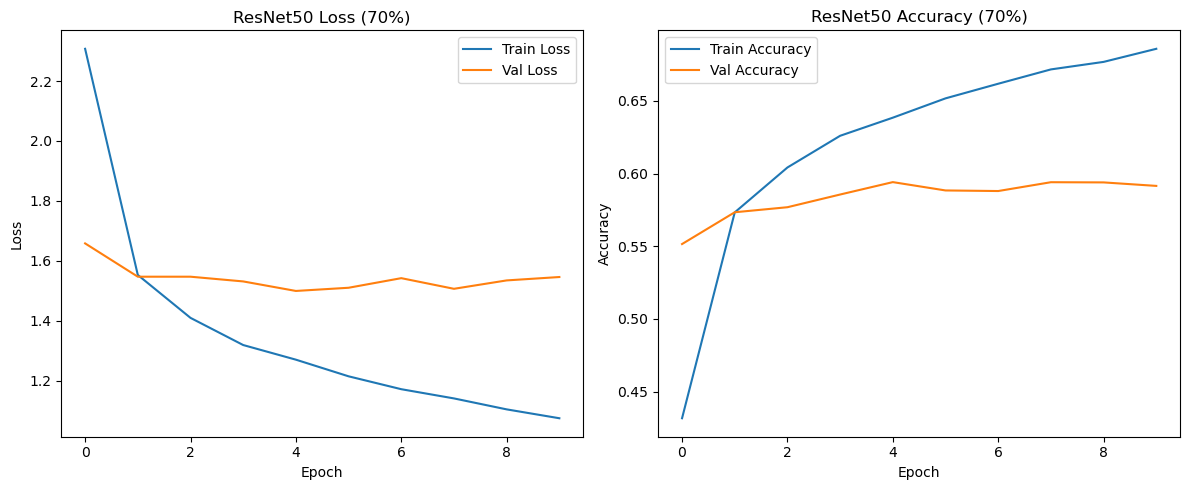


Final Evaluation for ResNet50 (70%):
Accuracy: 0.5839
Precision: 0.6378
Recall: 0.5839
F1: 0.5825


In [22]:
# Run training for different split ratios
models_to_run = {
    'VGG16': get_vgg16,
    'ResNet50': get_resnet50
}

split_ratios = [0.5, 0.6, 0.7]

for model_name, get_model_fn in models_to_run.items():
    for split_ratio in split_ratios:
        print(f"\n{model_name} - {int(split_ratio*100)}%")

        train_len = int(split_ratio * len(train_full))
        val_len = len(train_full) - train_len
        train_set, val_set = random_split(train_full, [train_len, val_len])
        train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
        val_loader = DataLoader(val_set, batch_size=64, shuffle=False)

        model = get_model_fn().to(device)

        train_losses, val_losses, train_accs, val_accs = train_model(model, train_loader, val_loader, epochs=10)

        plot_metrics(train_losses, val_losses, train_accs, val_accs, model_name, split_ratio)

        metrics = evaluate_model(model, test_loader)

        results['model'].append(model_name)
        results['split_ratio'].append(split_ratio)
        results['train_acc'].append(train_accs[-1])
        results['val_acc'].append(val_accs[-1])
        results['test_acc'].append(metrics['accuracy'])  

        print(f"\nFinal Evaluation for {model_name} ({int(split_ratio*100)}%):")
        for key, value in metrics.items():
            print(f"{key.capitalize()}: {value:.4f}")

In [23]:
# Results
df_results = pd.DataFrame(results)
display(df_results)

,model,split_ratio,train_acc,val_acc,test_acc
0,VGG16,0.5,0.660480,0.603040,0.6069
1,VGG16,0.6,0.647133,0.610100,0.6045
2,VGG16,0.7,0.636943,0.617933,0.6170
3,ResNet50,0.5,0.697360,0.574320,0.5733
4,ResNet50,0.6,0.691900,0.585050,0.5837
5,ResNet50,0.7,0.685829,0.591533,0.5839
